In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")

print("Final Data Science Project started successfully!")


Final Data Science Project started successfully!


In [2]:

from google.colab import files

uploaded = files.upload()


Saving student-mat.csv to student-mat.csv


In [3]:

df = pd.read_csv("student-mat.csv", sep=";")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())


Dataset loaded successfully!
Dataset shape: (395, 33)


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [4]:

print("Dataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum().sum())

print("\nDuplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("\nStatistical summary:")
display(df.describe())

print("\nFinal grade summary:")
print(df["G3"].describe())


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   school      395 non-null    object
 1   sex         395 non-null    object
 2   age         395 non-null    int64 
 3   address     395 non-null    object
 4   famsize     395 non-null    object
 5   Pstatus     395 non-null    object
 6   Medu        395 non-null    int64 
 7   Fedu        395 non-null    int64 
 8   Mjob        395 non-null    object
 9   Fjob        395 non-null    object
 10  reason      395 non-null    object
 11  guardian    395 non-null    object
 12  traveltime  395 non-null    int64 
 13  studytime   395 non-null    int64 
 14  failures    395 non-null    int64 
 15  schoolsup   395 non-null    object
 16  famsup      395 non-null    object
 17  paid        395 non-null    object
 18  activities  395 non-null    object
 19  nursery     395 non-null    o

,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
count,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000,395.000000
mean,16.696203,2.749367,2.521519,1.448101,2.035443,0.334177,3.944304,3.235443,3.108861,1.481013,2.291139,3.554430,5.708861,10.908861,10.713924,10.415190
std,1.276043,1.094735,1.088201,0.697505,0.839240,0.743651,0.896659,0.998862,1.113278,0.890741,1.287897,1.390303,8.003096,3.319195,3.761505,4.581443
min,15.000000,0.000000,0.000000,1.000000,1.000000,0.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000,3.000000,0.000000,0.000000
25%,16.000000,2.000000,2.000000,1.000000,1.000000,0.000000,4.000000,3.000000,2.000000,1.000000,1.000000,3.000000,0.000000,8.000000,9.000000,8.000000
50%,17.000000,3.000000,2.000000,1.000000,2.000000,0.000000,4.000000,3.000000,3.000000,1.000000,2.000000,4.000000,4.000000,11.000000,11.000000,11.000000
75%,18.000000,4.000000,3.000000,2.000000,2.000000,0.000000,5.000000,4.000000,4.000000,2.000000,3.000000,5.000000,8.000000,13.000000,13.000000,14.000000
max,22.000000,4.000000,4.000000,4.000000,4.000000,3.000000,5.000000,5.000000,5.000000,5.000000,5.000000,5.000000,75.000000,19.000000,19.000000,20.000000



Final grade summary:
count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64


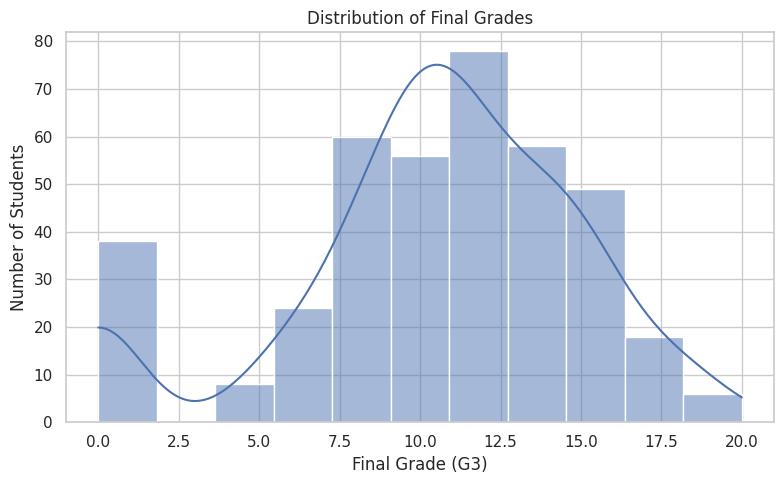

In [5]:

plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="G3", bins=11, kde=True)
plt.title("Distribution of Final Grades")
plt.xlabel("Final Grade (G3)")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()


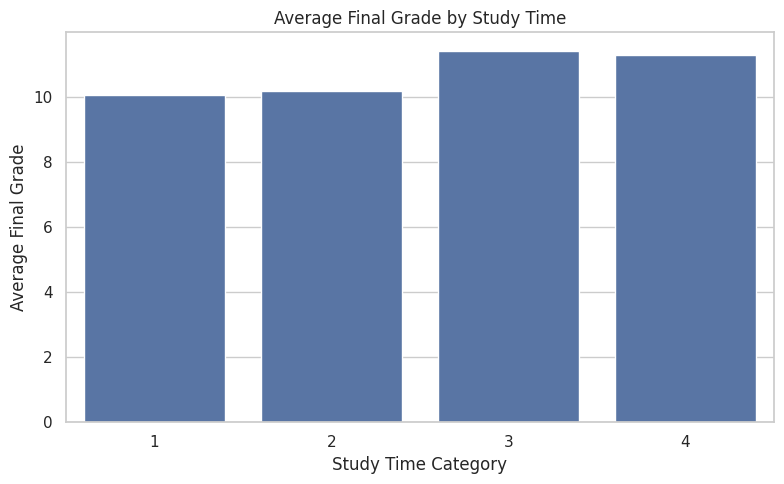

In [6]:

plt.figure(figsize=(8, 5))
sns.barplot(data=df, x="studytime", y="G3", errorbar=None)
plt.title("Average Final Grade by Study Time")
plt.xlabel("Study Time Category")
plt.ylabel("Average Final Grade")
plt.tight_layout()
plt.show()


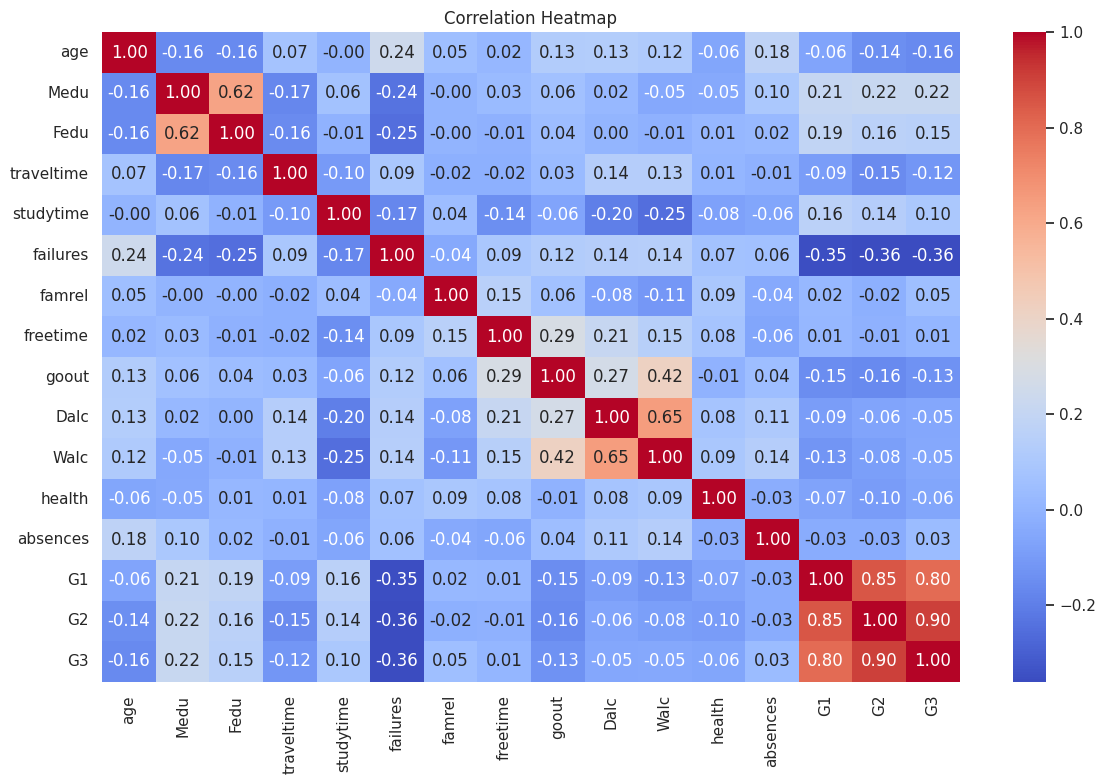

In [7]:

plt.figure(figsize=(12, 8))
sns.heatmap(
    df.select_dtypes(include="number").corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()


In [8]:

# Target: Final grade
target = "G3"

# Features: மற்ற columns
X = df.drop(columns=[target])
y = df[target]

# Numerical மற்றும் categorical columns கண்டறிதல்
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

print("Number of input features:", X.shape[1])
print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Number of input features: 32
Numerical features: 15
Categorical features: 17


In [9]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))


Training records: 316
Testing records: 79


In [10]:

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=200,
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Machine Learning model trained successfully!")


Machine Learning model trained successfully!


In [11]:

y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION")
print("=" * 35)
print(f"Mean Absolute Error (MAE): {mae:.2f}")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f}")
print(f"R² Score: {r2:.3f}")


MODEL EVALUATION
Mean Absolute Error (MAE): 1.19
Root Mean Squared Error (RMSE): 2.01
R² Score: 0.804


,Actual Grade,Predicted Grade
0,10,8.21
1,12,11.74
2,5,6.66
3,10,9.70
4,9,8.82
5,13,12.80
6,18,18.71
7,6,6.90
8,0,7.41
9,14,13.34


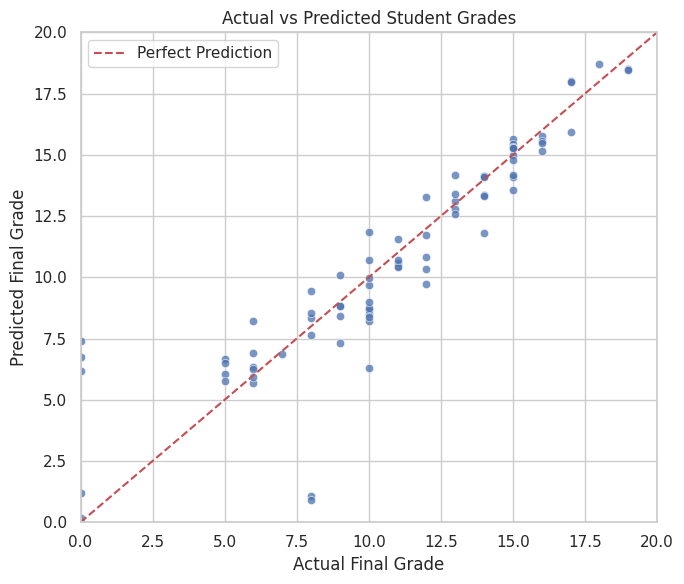

In [12]:

comparison = pd.DataFrame({
    "Actual Grade": y_test.values,
    "Predicted Grade": np.round(y_pred, 2)
})

display(comparison.head(10))

plt.figure(figsize=(7, 6))
sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.75
)

plt.plot([0, 20], [0, 20], "r--", label="Perfect Prediction")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.xlabel("Actual Final Grade")
plt.ylabel("Predicted Final Grade")
plt.title("Actual vs Predicted Student Grades")
plt.legend()
plt.tight_layout()
plt.show()


,Feature,Importance
14,num__G2,0.787204
12,num__absences,0.114331
36,cat__reason_home,0.018982
0,num__age,0.009070
13,num__G1,0.005542
6,num__famrel,0.004970
11,num__health,0.004063
40,cat__guardian_mother,0.003701
8,num__goout,0.003611
4,num__studytime,0.003205


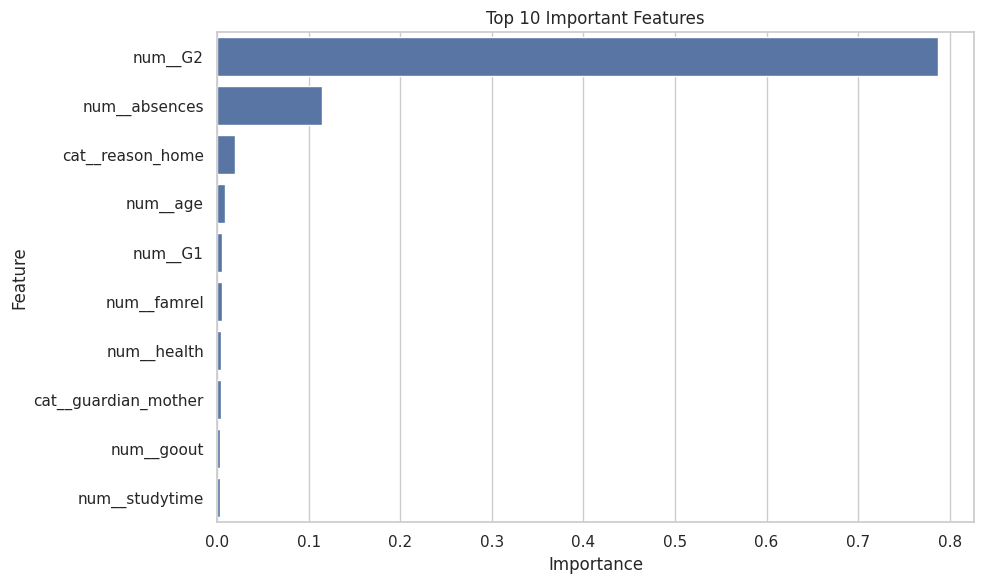

In [13]:

feature_names = model.named_steps["preprocessor"].get_feature_names_out()
importances = model.named_steps["regressor"].feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
}).sort_values("Importance", ascending=False)

display(importance_df.head(10))

plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)
plt.title("Top 10 Important Features")
plt.tight_layout()
plt.show()


In [14]:

pass_rate = (df["G3"] >= 10).mean() * 100

print("FINAL PROJECT FINDINGS")
print("=" * 45)
print(f"Total students analyzed: {len(df)}")
print(f"Average final grade: {df['G3'].mean():.2f}/20")
print(f"Pass rate (G3 >= 10): {pass_rate:.2f}%")
print(f"Model MAE: {mae:.2f}")
print(f"Model RMSE: {rmse:.2f}")
print(f"Model R² score: {r2:.3f}")
print("\nTop 5 important features:")
display(importance_df.head(5))


FINAL PROJECT FINDINGS
Total students analyzed: 395
Average final grade: 10.42/20
Pass rate (G3 >= 10): 67.09%
Model MAE: 1.19
Model RMSE: 2.01
Model R² score: 0.804

Top 5 important features:


,Feature,Importance
14,num__G2,0.787204
12,num__absences,0.114331
36,cat__reason_home,0.018982
0,num__age,0.009070
13,num__G1,0.005542


## Conclusion

This final project demonstrates an end-to-end data science workflow using the UCI Student Performance dataset.

The project included data inspection, data cleaning, exploratory data analysis, statistical summaries, and visualizations to explore students' academic performance.

A Random Forest Regression model was developed to predict students' final grades using previous grades and other available student information. The dataset was divided into training and testing sets to evaluate the model on unseen records.

The model achieved a Mean Absolute Error (MAE) of **1.19**, a Root Mean Squared Error (RMSE) of **2.01**, and an R² score of **0.804** on the test set. These results indicate that the model performed well on this test split, although its performance may vary on other data.

The analysis covered 395 student records,